In [17]:
from typing import TypedDict, Annotated, List, Literal, Dict, Any
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage, SystemMessage
from langgraph.graph import StateGraph, END, MessagesState, START
from langgraph.checkpoint.memory import MemorySaver
import random
from datetime import datetime
from langchain_core.prompts import ChatPromptTemplate

In [28]:
from langchain_groq import ChatGroq

supervisor_llm = ChatGroq(
    model="qwen/qwen3.8-27b",
    max_tokens=300
)
agent_llm = ChatGroq(
    model="qwen/qwen3.8-27b",
    max_tokens=300
)

In [3]:

class HierarchicalState(MessagesState):
    task: str
    next_agent: str

    data_research: str
    market_research: str

    research_report: str
    technical_report: str
    summary: str
    final_report: str

    current_stage: str
    task_complete: bool


In [4]:

def create_ceo_chain():
    ceo_prompt = ChatPromptTemplate.from_messages([
        (
            "system",
            """You are the CEO supervising a hierarchical AI team.

Your team contains:
- research_team_leader: coordinates data and market researchers
- writing_team_leader: coordinates technical and summary writers

Choose the next agent based on the task progress.

Rules:
- If research is not complete, choose research_team_leader.
- If research is complete but writing is not complete,
  choose writing_team_leader.
- If the final report is ready, choose DONE.

Current state:
- Research complete: {research_complete}
- Writing complete: {writing_complete}

Return ONLY one of these values:
research_team_leader
writing_team_leader
DONE
"""
        ),
        ("human", "{task}")
    ])

    return ceo_prompt | supervisor_llm



In [5]:

def ceo_agent(state: HierarchicalState) -> dict:
    task = state.get("task", "")

    research_complete = bool(
        state.get("research_report", "")
    )

    writing_complete = bool(
        state.get("final_report", "")
    )

    chain = create_ceo_chain()

    decision = chain.invoke({
        "task": task,
        "research_complete": research_complete,
        "writing_complete": writing_complete
    })

    decision_text = decision.content.strip().lower()

    print("CEO decision:", decision_text)

    if "done" in decision_text or writing_complete:
        next_agent = "end"
        message = "CEO: The report is complete."

    elif (
        "writing_team_leader" in decision_text
        or research_complete
    ):
        next_agent = "writing_team_leader"
        message = "CEO: Research completed. Assigning the writing team."

    else:
        next_agent = "research_team_leader"
        message = "CEO: Assigning the research team."

    return {
        "messages": [AIMessage(content=message)],
        "next_agent": next_agent
    }


In [6]:

def data_researcher(state: HierarchicalState) -> dict:
    task = state.get("task", "")

    prompt = f"""
    You are a data research specialist.

    Research the following topic: {task}

    Provide:
    1. Important facts and background
    2. Relevant data and statistics, when known
    3. Current trends
    4. Reliable examples

    Do not invent statistics. Clearly mention uncertainty.
    Be concise and structured.
    """

    response = agent_llm.invoke([
        HumanMessage(content=prompt)
    ])

    research = response.content

    return {
        "data_research": research,
        "messages": [
            AIMessage(content="Data Researcher: Research completed.")
        ],
        "next_agent": "market_researcher"
    }

In [7]:

def market_researcher(state: HierarchicalState) -> dict:
    task = state.get("task", "")
    data_research = state.get("data_research", "")

    prompt = f"""
    You are a market research specialist.

    Topic: {task}

    General research already collected:
    {data_research[:3000]}

    Analyze:
    1. Market trends and customer needs
    2. Main actors and competitors, when relevant
    3. Opportunities and challenges
    4. Potential risks

    Do not invent facts or market statistics.
    Clearly distinguish evidence from assumptions.
    Be concise and structured.
    """

    response = agent_llm.invoke([
        HumanMessage(content=prompt)
    ])

    research = response.content

    return {
        "market_research": research,
        "messages": [
            AIMessage(content="Market Researcher: Research completed.")
        ],
        "next_agent": "research_team_leader"
    }


In [8]:

def research_team_leader(
    state: HierarchicalState
) -> dict:

    data_research = state.get("data_research", "")
    market_research = state.get("market_research", "")

    if not data_research:
        next_agent = "data_researcher"
        message = "Research Leader: Starting data research."

    elif not market_research:
        next_agent = "market_researcher"
        message = "Research Leader: Starting market research."

    else:
        research_report = f"""
        RESEARCH REPORT

        GENERAL DATA AND FINDINGS
        {data_research}

        MARKET RESEARCH
        {market_research}
        """

        return {
            "research_report": research_report,
            "messages": [
                AIMessage(
                    content="Research Leader: Research report completed."
                )
            ],
            "next_agent": "ceo"
        }

    return {
        "messages": [AIMessage(content=message)],
        "next_agent": next_agent
    }


In [9]:

def technical_writer(state: HierarchicalState) -> dict:
    task = state.get("task", "")
    research_report = state.get("research_report", "")

    prompt = f"""
    You are a technical writer.

    Topic: {task}

    Research findings:
    {research_report[:4000]}

    Write a detailed and structured report containing:
    1. Background and context
    2. Technical explanation
    3. Key findings
    4. Challenges and limitations
    5. Practical recommendations

    Do not invent facts or statistics.
    Be clear, professional, and precise.
    """

    response = agent_llm.invoke([
        HumanMessage(content=prompt)
    ])

    technical_report = response.content

    return {
        "technical_report": technical_report,
        "messages": [
            AIMessage(content="Technical Writer: Report drafted.")
        ],
        "next_agent": "summary_writer"
    }


In [15]:

def summary_writer(state: HierarchicalState) -> dict:
    task = state.get("task", "")
    research_report = state.get("research_report", "")
    technical_report = state.get("technical_report", "")

    prompt = f"""
    You are an executive summary writer.

    Topic: {task}

    Research findings:
    {research_report[:2500]}

    Technical report:
    {technical_report[:3500]}

    Write a concise executive summary containing:
    1. The objective
    2. The most important findings
    3. The main implications
    4. The key recommendations
    5. The conclusion

    Do not repeat every detail.
    Do not invent facts.
    Use clear, professional language.
    """

    response = agent_llm.invoke([
        HumanMessage(content=prompt)
    ])

    summary = response.content

    return {
        "summary": summary,
        "messages": [
            AIMessage(content="Summary Writer: Summary completed.")
        ],
        "next_agent": "writing_team_leader"
    }


In [10]:

def writing_team_leader(
    state: HierarchicalState
) -> dict:

    technical_report = state.get("technical_report", "")
    summary = state.get("summary", "")
    task = state.get("task", "")

    if not technical_report:
        return {
            "messages": [
                AIMessage(
                    content="Writing Leader: Starting technical writing."
                )
            ],
            "next_agent": "technical_writer"
        }

    if not summary:
        return {
            "messages": [
                AIMessage(
                    content="Writing Leader: Starting summary writing."
                )
            ],
            "next_agent": "summary_writer"
        }

    final_report = f"""
FINAL REPORT
Generated: {datetime.now().strftime('%Y-%m-%d %H:%M')}
Topic: {task}

{'=' * 50}

EXECUTIVE SUMMARY

{summary}

{'=' * 50}

TECHNICAL REPORT

{technical_report}

{'=' * 50}

Generated by the Hierarchical AI Agent System.
"""

    return {
        "final_report": final_report,
        "task_complete": True,
        "messages": [
            AIMessage(
                content="Writing Leader: Final report assembled."
            )
        ],
        "next_agent": "ceo"
    }


In [11]:

def router(state: HierarchicalState) -> str:
    next_agent = state.get("next_agent", "ceo")

    if next_agent == "end" or state.get("task_complete", False):
        return END

    allowed_agents = {
        "ceo",
        "research_team_leader",
        "data_researcher",
        "market_researcher",
        "writing_team_leader",
        "technical_writer",
        "summary_writer"
    }

    if next_agent in allowed_agents:
        return next_agent

    return "ceo"


In [32]:
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver

workflow = StateGraph(HierarchicalState)

# 1. Déclarer les nœuds
workflow.add_node("ceo", ceo_agent)
workflow.add_node("research_team_leader", research_team_leader)
workflow.add_node("data_researcher", data_researcher)
workflow.add_node("market_researcher", market_researcher)
workflow.add_node("writing_team_leader", writing_team_leader)
workflow.add_node("technical_writer", technical_writer)
workflow.add_node("summary_writer", summary_writer)

# 2. Point de départ
workflow.add_edge(START, "ceo")

# 3. Définir les destinations autorisées du routeur
path_map = {
    "ceo": "ceo",
    "research_team_leader": "research_team_leader",
    "data_researcher": "data_researcher",
    "market_researcher": "market_researcher",
    "writing_team_leader": "writing_team_leader",
    "technical_writer": "technical_writer",
    "summary_writer": "summary_writer",
    "end": END,
}

# 4. Ajouter le routage conditionnel depuis chaque nœud
for node in [
    "ceo",
    "research_team_leader",
    "data_researcher",
    "market_researcher",
    "writing_team_leader",
    "technical_writer",
    "summary_writer",
]:
    workflow.add_conditional_edges(node, router, path_map)

# 5. Compiler
memory = MemorySaver()
app = workflow.compile(checkpointer=memory)
memory=MemorySaver()
app=workflow.compile(checkpointer=memory)


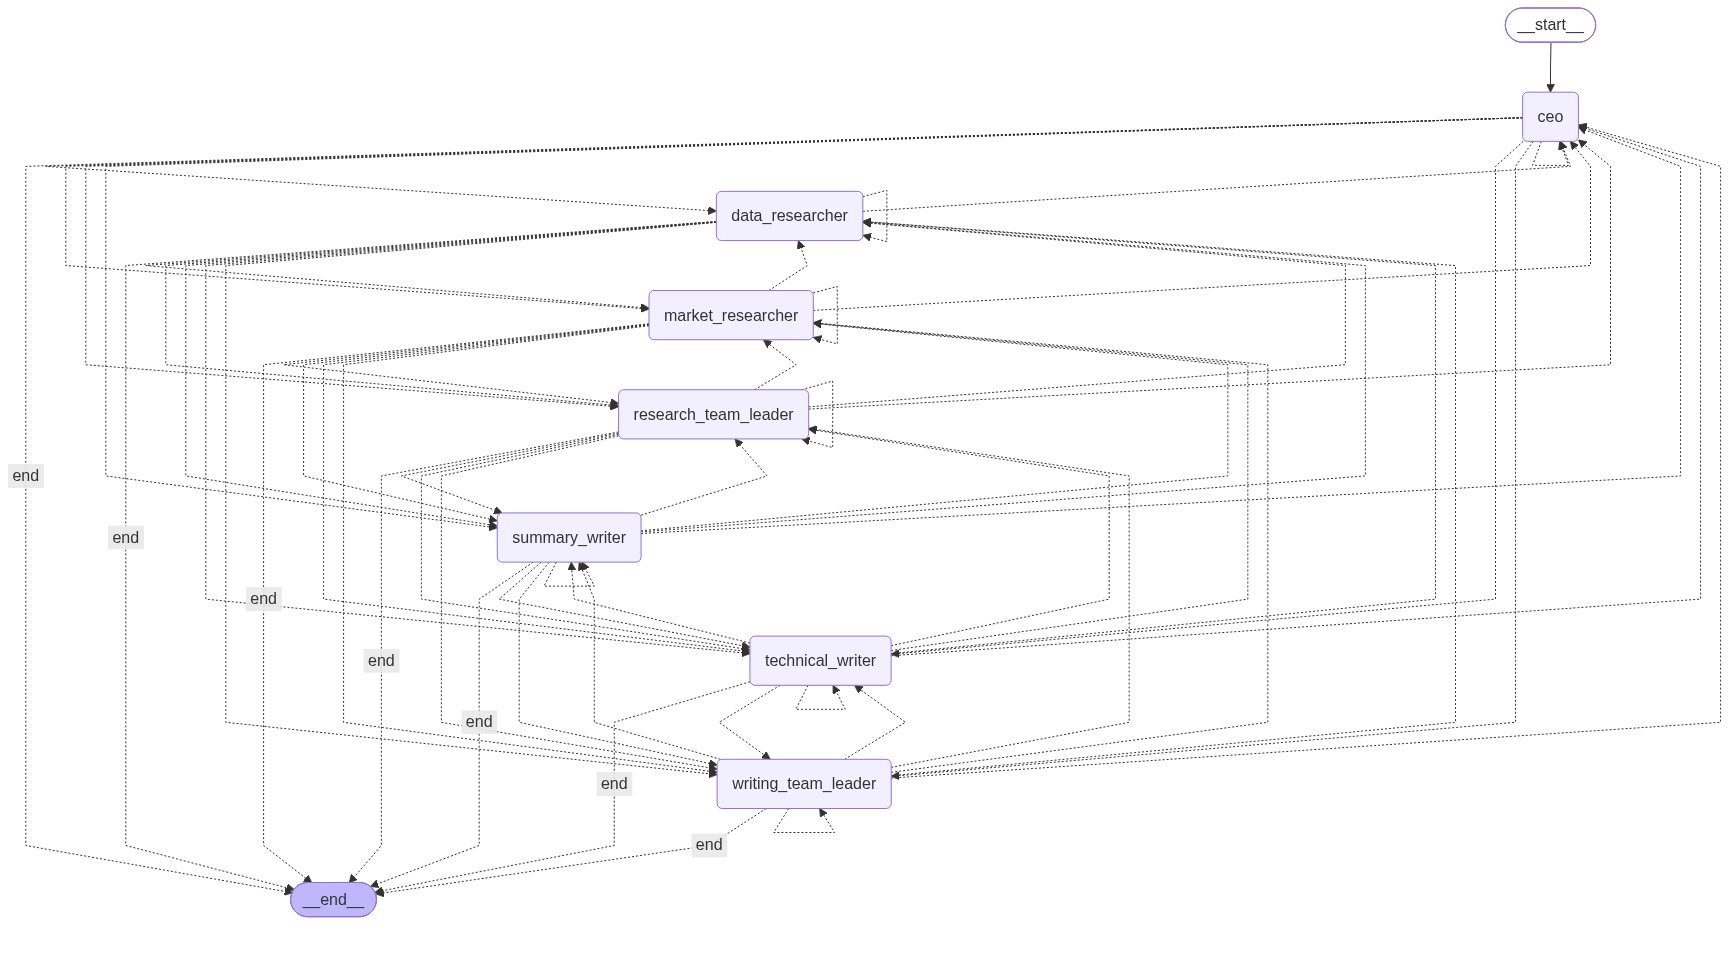

In [33]:
from IPython.display import Image, display

display(Image(app.get_graph().draw_mermaid_png()))

In [29]:

initial_state = {
    "messages": [
        HumanMessage(
            content="Research AI in education and create a report"
        )
    ],
    "task": "AI in education",
    "next_agent": "ceo",
    "data_research": "",
    "market_research": "",
    "research_report": "",
    "technical_report": "",
    "summary": "",
    "final_report": "",
    "current_stage": "research",
    "task_complete": False
}

result = app.invoke(
    initial_state,
    config={"configurable": {"thread_id": "ai-education-1"}}
)

print(result["final_report"])


CEO decision: research_team_leader
CEO decision: writing_team_leader

FINAL REPORT
Generated: 2026-10-13 00:03
Topic: AI in education


EXECUTIVE SUMMARY

**Executive Summary: AI in Education**

**Objective**
This report examines the current state of Artificial Intelligence (AI) in education, analyzing market trends, technical capabilities, and stakeholder needs to assess the sector’s trajectory and strategic value.

**Key Findings**
The AI in education sector is experiencing rapid expansion, with the global market valued at approximately $2–3 billion in 2023 and projected to grow at a CAGR of 30–40% through 2030. A significant shift is occurring from early applications focused on administrative automation (such as grading and scheduling) to pedagogical support. Driven by advancements in Large Language Models (LLMs) and generative AI, the industry is moving toward dynamic, personalized learning environments that offer real-time tutoring, adaptive content generation, and enhanced access